## Rouse polymer

In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import json
import os

### Load data

In [24]:
import json, glob
import numpy as np

# _data_dir = "data/20260528/rouse_mfpt_attractive"
_data_dir = "data/20260611/rouse_mfpt_attractive"
_files = sorted(glob.glob(f"{_data_dir}/output_cpu*.json"))

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
for _path in _files:
    with open(_path, 'r') as _f:
        _raw = json.load(_f)
    _cpu_id = list(_raw.keys())[0]
    for _run_id, _run in _raw[_cpu_id].items():
        _alpha = _run["alpha"]
        data[_alpha] = _run

# --- sort alphas ---
alphas = np.array(sorted(data.keys()))
nparams = len(alphas)

# infer params from first entry
_first = data[alphas[0]]
params         = _first["rouse_params"]
nsteps_distance = int(params["nsteps"] / _first["sample_skip"])
# nsteps_full     = params["nsteps_full"]
dt              = params["dt"]

t_grid_distance = np.arange(nsteps_distance) * dt
# t_grid_full     = np.arange(nsteps_full) * dt
nsteps_pot     = len(_first["total_potential"])

# pre-allocate (sizes inferred from first entry)
# _nfpt = len(_first["contact_times"])
# _nicdf = len(_first["inverse_cdf"])
# _nhist = len(_first["hist_centers"])
# _nmsd  = len(_first["msd_bead1"])

distance_traj    = np.empty((nparams, nsteps_distance))
# contact_times    = [None] * nparams   # variable-length per alpha
# inverse_cdf      = [None] * nparams
# hist_centers     = np.empty((nparams, _nhist))
# hist_counts      = np.empty((nparams, _nhist))
# msd_bead1        = np.empty((nparams, _nmsd))
# msd_beadMid      = np.empty((nparams, _nmsd))
# msd_pairDistance = np.empty((nparams, _nmsd))
total_potential    = np.empty((nparams, nsteps_pot))
runtime_min      = np.empty(nparams)

for _ic, _alpha in enumerate(alphas):
    _r = data[_alpha]
    distance_traj[_ic]    = np.array(_r["distance_traj"])
    total_potential[_ic]  = np.array(_r["total_potential"])
    # contact_times[_ic]    = np.array(_r["contact_times"])
    # inverse_cdf[_ic]      = np.array(_r["inverse_cdf"])
    # hist_centers[_ic]     = np.array(_r["hist_centers"])
    # hist_counts[_ic]      = np.array(_r["hist_counts"])
    # msd_bead1[_ic]        = np.array(_r["msd_bead1"])
    # msd_beadMid[_ic]      = np.array(_r["msd_beadMid"])
    # msd_pairDistance[_ic] = np.array(_r["msd_pairDistance"])
    runtime_min[_ic]      = _r["runtime_min"]

### Distance trace

nsteps:  20000
total physical time:  333.3333333333333
bead relaxation time:  0.3333333333333333


(10.0, 200.0)

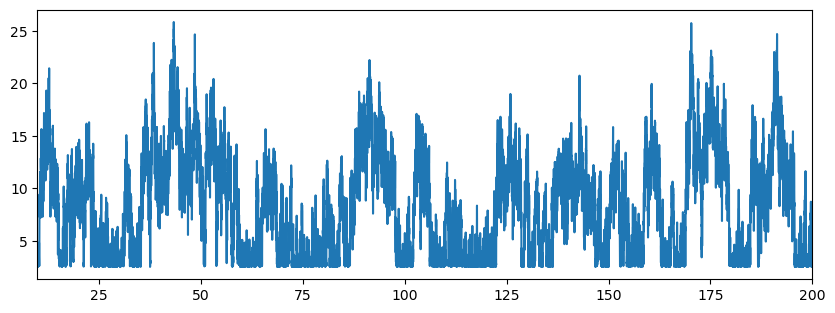

In [25]:
fig, ax = plt.subplots(1,1,figsize=(10, 3.5))

ax.plot(t_grid_distance, distance_traj[15])
print("nsteps: ", nsteps_distance)
print("total physical time: ", dt*nsteps_distance)
print("bead relaxation time: ", _first["bead_relax_time"])
ax.set_xlim(10, 200)

### Distance hist

0.101


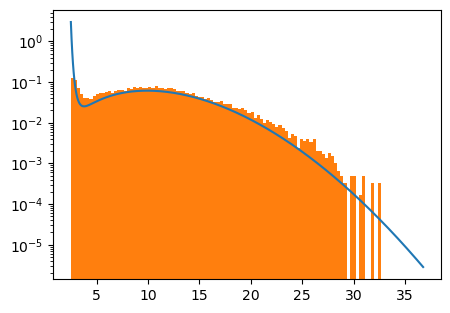

In [26]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))

keya = 10
b = _first["rouse_params"]["kuhn_length"]
R = _first["surface_params"]["R"]
subsampled = distance_traj[keya, ::1].T
subsampled = subsampled[subsampled > 0.5]

N = 150
# dist = xs**2 * np.exp(-3*xs**2/(2*N*b**2))
# dist = dist / np.sum(dist)

pot = total_potential[keya][1:]
xs = np.linspace(R, 3*np.sqrt(N)*b, len(pot))
P_eq = np.exp(-pot)
P_eq /= np.trapz(P_eq, xs)

ax.plot(xs, P_eq)
_=ax.hist(subsampled, density=True, bins=100)
# ax.axvline(np.sqrt(N)*b)
ax.set_yscale('log')
print(alphas[keya])


In [ ]:
out_dir = "media/figures/20260528"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_distance_distribution_hic.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260528/rouse_distance_distribution_hic.pdf


### Total potential

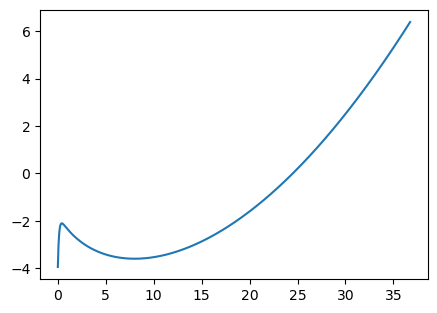

In [29]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))

keya = 1
R = _first["surface_params"]["R"]
xs = np.linspace(0, 3*np.sqrt(N)*b, len(total_potential[keya]))

ax.plot(xs, total_potential[keya])

#### Recovering exit rate

In [ ]:
r_traj = sim.r[:, 0, :]
limit = x_bar
crossed = r_traj > limit
first_exit = np.where(crossed.any(0), crossed.argmax(0), sim.ns)
mask = np.arange(sim.ns)[burn:, None] < first_exit[None, :]

1000/1000 trajectories exited
empirical rate  k = 1/<T_exit> = 0.0020
Kramers   rate  k             = 0.0022
ratio empirical / Kramers     = 0.94


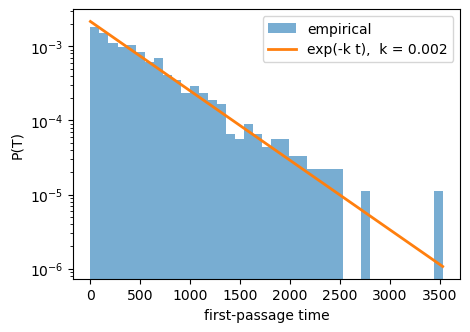

In [ ]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
exited = (sim.r[:, 0, :] > limit).any(0)
fpt = first_exit[exited] * sim.dt * sim.nskip
print(f"{exited.sum()}/{sim.N} trajectories exited")

D = (kB * T_bath) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 2.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 40)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")

### Contact times

In [ ]:
# fig, ax = plt.subplots(1,1,figsize=(5, 3.5))



### Mean-squared displacement

Text(0.5, 1.0, 'single locus')

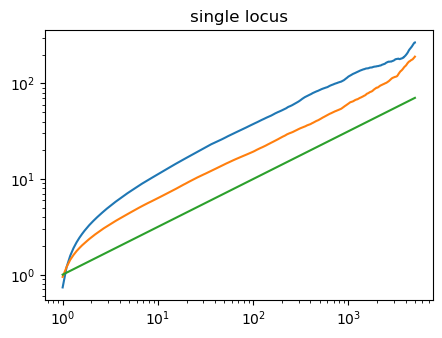

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))
maxlag = dt*len(msd_bead1[0])
msd_time = np.linspace(1, maxlag, len(msd_bead1[0]))
_=ax.plot(msd_time, msd_bead1[0])
_=ax.plot(msd_time, msd_beadMid[0])
ax.plot(msd_time, msd_time**0.5)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_title("single locus")

Text(0.5, 1.0, 'two locus')

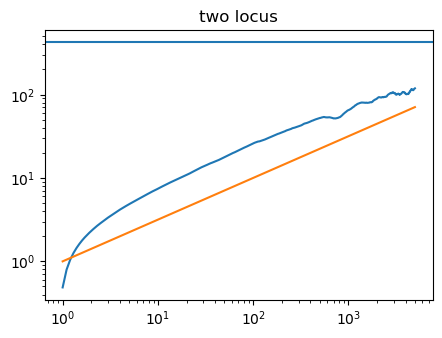

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))
maxlag = dt*len(msd_bead1[0])
msd_time = np.linspace(1, maxlag, len(msd_bead1[0]))
_=ax.plot(msd_time, msd_pairDistance[0])
ax.plot(msd_time, msd_time**0.5)
ax.axhline(y=np.mean(distance_traj**2))
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_title("two locus")

### Fisher rates from polymer open/close dynamics

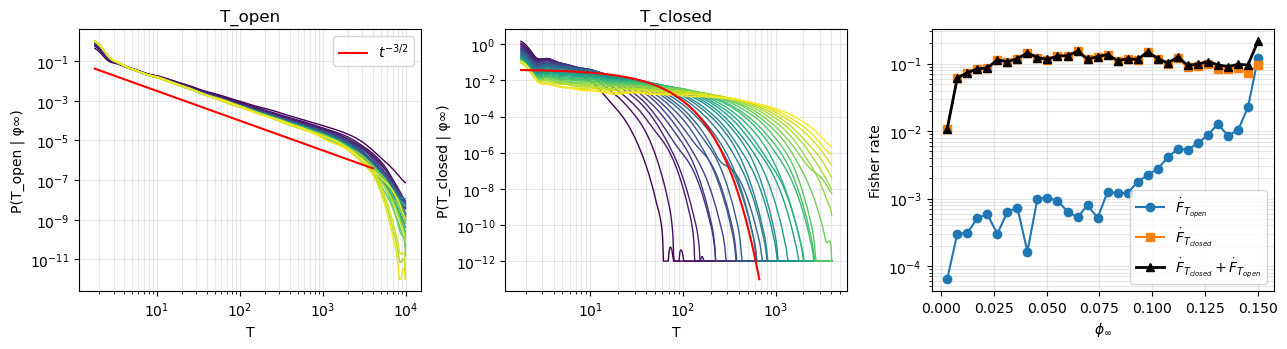

In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt

PATH = "media/figures/20260528/rouse_mfpt_attractive_fisher_hires.json"

with open(PATH) as f:
    blob = json.load(f)

# scalars / arrays indexed by phi_inf
phi_inf    = np.asarray(blob["phi_inf"], dtype=float)
d_ridge    = np.asarray(blob["d_ridge"], dtype=float)
joint_rate = np.asarray(blob["joint_rate"], dtype=float)

# helper: JSON-encoded arrays may contain `None` where the analysis produced
# a NaN (empty histogram bin, log of 0, etc.). Cast back to NaN for math.
def arr(x):
    return np.asarray(x, dtype=float)   # None -> NaN automatically

def unpack(group):
    return dict(
        T_grid           = arr(group["T_grid"]),            # (n_T,)
        pdfs             = arr(group["pdfs"]),              # (n_phi, n_T)
        mean_T           = arr(group["mean_T"]),            # (n_phi,)
        fisher_per_event = arr(group["fisher_per_event"]),  # (n_phi,) wrt log phi
        fisher_rate      = arr(group["fisher_rate"]),       # (n_phi,) per unit time
    )

open_  = unpack(blob["open"])
closed = unpack(blob["closed"])

# ---- quick sanity plots --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
cmap = plt.get_cmap("viridis")

for name, g in [("T_open", open_), ("T_closed", closed)]:
    ax = axes[0] if name == "T_open" else axes[1]
    for i in range(len(phi_inf)):
        if not np.all(np.isnan(g["pdfs"][i])):
            ax.loglog(g["T_grid"], np.clip(g["pdfs"][i], 1e-12, None),
                      color=cmap(i / max(1, len(phi_inf) - 1)), lw=1.0)
    ax.set_xlabel("T"); ax.set_ylabel(f"P({name} | φ∞)")
    ax.set_title(name); ax.grid(True, which="both", alpha=0.3)

lam = 0.04
stop=int(len(g["T_grid"]) / 1.3)
axes[0].plot(g["T_grid"], g["T_grid"]**(-3/2)*0.1, color="red", label=r"$t^{-3/2}$")
axes[0].legend()
axes[1].plot(g["T_grid"][:stop], lam*np.exp(-g["T_grid"][:stop]*lam), color="red")

ax = axes[2]
ax.plot(phi_inf, open_["fisher_rate"],   "o-", label=r"$\dot F_{T_{open}}$")
ax.plot(phi_inf, closed["fisher_rate"],  "s-", label=r"$\dot F_{T_{closed}}$")
ax.plot(phi_inf, joint_rate,             "^-", color="k", lw=2, label=r"$\dot F_{T_{closed}}+\dot F_{T_{open}}$")
ax.set_xlabel(r"$\phi_\infty$"); ax.set_ylabel("Fisher rate")
ax.set_yscale("log"); ax.legend(); ax.grid(True, which="both", alpha=0.3)

plt.tight_layout(); plt.show()

In [ ]:
out_dir = "media/figures/20260528"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fpt_pdfs_open_close_fisher_rates.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260528/fpt_pdfs_open_close_fisher_rates.pdf


### Recovering the Arrhenius exit time

#### Overdamped Langevin with arbitrary force

In [5]:
import abc
import numpy as np
from typing import Optional, Callable

class Generator(metaclass=abc.ABCMeta):
    """Abstract trajectory generator."""

    def __init__(
        self,
        T: float,
        dim: int = 1,
        N: int = 1,
        dt: float = 1.0,
        seed: Optional[int] = None,
    ):
        self.T = T                # Total time
        self.dim = dim
        self.N = N
        self.dt = dt
        self.n = int(T / dt)
        self.rng = (
            np.random.default_rng(seed) if seed is not None else np.random.default_rng()
        )

    @abc.abstractmethod
    def generate(self):
        ...

class OverdampedHarmonicLangevin(Generator):
    """
    Overdamped Langevin dynamics with an arbitrary spatial force F(r):

        gamma dr/dt = F(r) + sqrt(2 kB T gamma) eta(t),
        <eta(t) eta(t')> = delta(t - t')

    Euler-Maruyama in physical units, optionally with reflecting walls.

    Parameters
    ----------
    tau, dim, N, dt, gamma, kB, T, F, r0, seed : as before.
    r_min, r_max : float, optional
        If given, coordinates are reflected at these walls after each step.
        Use r_min to keep trajectories away from singularities like 1/r.
    """

    def __init__(
        self,
        tau: float,
        dim: int = 1,
        N: int = 1,
        nskip: int = 1,
        dt: float = 1.0,
        gamma: float = 1.0,
        kB: float = 1.0,
        T: float = 1.0,
        F: Optional[Callable] = None,
        r0: Optional[np.ndarray] = None,
        r_min: Optional[float] = None,
        r_max: Optional[float] = None,
        seed: Optional[int] = None,
    ):
        super().__init__(tau, dim, N, dt, seed)
        self.traj_id = "Overdamped Langevin with arbitrary force"

        self.nskip = nskip
        self.ns = (self.n - 1) // nskip + 1          # robust to n % nskip != 0


        self.T_bath = T

        if not callable(F):
            raise ValueError(
                "F is expected to be a callable F(r) -> force, with r and the "
                "return value of shape (dim, N)."
            )
        self.F = F

        self.kB = kB
        self.gamma = gamma
        self.r0 = r0

        self.r_min = r_min
        self.r_max = r_max

        self.shape = (self.ns, self.dim, self.N)
        self.r = np.empty(self.shape)

        self._set_init_cond()
        # self._set_noise()

    def _set_init_cond(self):
        if self.r0 is None:
            self.r[0] = 0.0

        elif np.shape(self.r0) == (self.dim, self.N) or np.ndim(self.r0) == 0:
            self.r[0] = self.r0
        else:
            raise ValueError(
                "r0 is expected to be a float or an "
                f"array of shape {(self.dim, self.N)}"
            )

    def _set_noise(self):
        self.noise = self.rng.normal(size=(self.dim, self.N))   # was (1, dim, N)

    def _solve(self):
        sqrt_dt = np.sqrt(self.dt)
        diff = np.sqrt(2.0 * self.kB * self.T_bath / self.gamma)
        inv_gamma = 1.0 / self.gamma
        r_min, r_max = self.r_min, self.r_max

        r_curr = self.r[0].copy()                 # high-res state; r[0] stays the IC
        for i in range(1, self.n):                # i = high-res step index
            self._set_noise()
            r_curr = (
                r_curr
                + self.F(r_curr) * inv_gamma * self.dt
                + diff * sqrt_dt * self.noise
            )
            if r_min is not None:
                r_curr = np.where(r_curr < r_min, 2 * r_min - r_curr, r_curr)
            if r_max is not None:
                r_curr = np.where(r_curr > r_max, 2 * r_max - r_curr, r_curr)

            if i % self.nskip == 0:
                j = i // self.nskip
                if j < self.ns:
                    self.r[j] = r_curr

    def generate(self):
        self._solve()


#### Checking the equilibrium distribution for a harmonic potential

In [53]:
k = 3
gamma = 0.5
dt = 0.01 * gamma / k   # choose much smaller than characteristic time
sim = OverdampedHarmonicLangevin(
    tau=500000*dt, dim=1, N=1, dt=dt,
    T=1.0, F=lambda r: -k * r,
    gamma = gamma, nskip = 10
)
sim.generate()

empirical Var(r) = 0.33881069274285786   expected = 0.3333333333333333


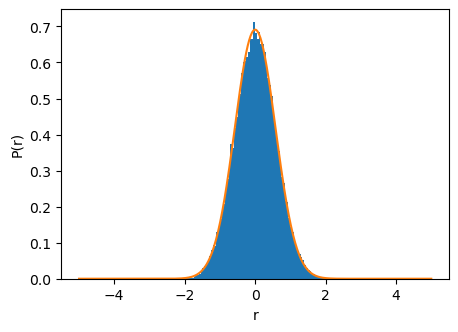

In [54]:
fig, ax = plt.subplots(1,1,figsize=(5,3.5))

xs = np.linspace(-5, 5, 500)
var = sim.kB * sim.T_bath / k       # OU stationary variance for F = -k r
dist = np.exp(-xs**2/(2*var)) / np.sqrt(2*np.pi*var)

# discard burn-in (a few relaxation times tau_relax = gamma/k)
burn = int(5 * gamma / k / sim.dt)
ax.hist(sim.r[burn:,0,0].flatten(), bins=100, density=True)
# ax.hist(sim.r[-1,0,:].flatten(), bins=100, density=True)
ax.plot(xs, dist)
ax.set_xlabel("r"); ax.set_ylabel("P(r)")
print("empirical Var(r) =", sim.r[burn:,0,0].var(), "  expected =", var)

### A simple potential with well and barrier 

left well  : r=0.010, U=0.109, ω_well=0.876
barrier    : r=1.515,  U=1.023,  ω_bar =1.407
ΔU = 0.914


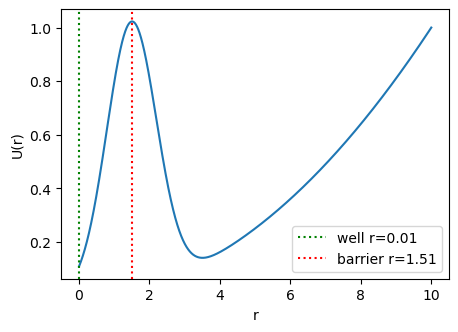

In [3]:
# Double-well potential: 1/(100|r|) keeps r > 0, Gaussian creates the barrier,
# 0.01 r^2 confines at large r.
args = (100, 1.5, 0.5, 0.01)


def U(x, *args):
    a, b, c, d = args
    # return 1.0 / np.abs(a * x) + np.exp(-(x - b) ** 2 / (2 * c)) + d * x ** 2
    return np.exp(-(x - b) ** 2 / (2 * c)) + d * x ** 2


def F(x, *args):
    """Analytic force F = -dU/dx (only valid for x > 0)."""
    a, b, c, d = args
    # return 1.0 / (a * x ** 2) + (x - b) / c * np.exp(-(x - b) ** 2 / (2 * c)) - 2 * d * x
    return (x - b) / c * np.exp(-(x - b) ** 2 / (2 * c)) - 2 * d * x


# --- locate left well, barrier; compute ΔU and curvatures ---
xs = np.linspace(1e-2, 10, 5000)
U_vals = U(xs, *args)

left = xs < 2.0
right = xs > 2.0
i_well = np.argmin(U_vals[left])
i_barrier = (np.argmax(U_vals[left]) if False
             else np.argmax(U_vals * ((xs > xs[left][i_well]) & (xs < 3.5))))

x_well, U_well = xs[left][i_well], U_vals[left][i_well]
x_bar,  U_bar = xs[i_barrier],   U_vals[i_barrier]
dU = U_bar - U_well

# numerical curvatures


def d2U(x):
    h = 1e-3
    return (U(x + h, *args) - 2 * U(x, *args) + U(x - h, *args)) / h ** 2


omega_well = np.sqrt(d2U(x_well))     # >0
omega_bar = np.sqrt(-d2U(x_bar))      # |U''| at the saddle

print(f"left well  : r={x_well:.3f}, U={U_well:.3f}, ω_well={omega_well:.3f}")
print(f"barrier    : r={x_bar:.3f},  U={U_bar:.3f},  ω_bar ={omega_bar:.3f}")
print(f"ΔU = {dU:.3f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.plot(xs, U_vals)
ax.axvline(x_well, color="g", ls=":", label=f"well r={x_well:.2f}")
ax.axvline(x_bar,  color="r", ls=":", label=f"barrier r={x_bar:.2f}")
ax.set_xlabel("r")
ax.set_ylabel("U(r)")
ax.legend()

#### Simulating Langevin under that potential

In [10]:
# --- parameter selection -------------------------------------------------
# 1) Temperature: ΔU/(kBT) in [3, 7] is the Arrhenius sweet spot --- escape
#    is rare enough to be exponentially distributed, frequent enough to
#    collect statistics in reasonable wall-clock time.
T_bath = 0.15                    # -> ΔU/T ≈ 4.6 here
gamma  = 1.0
kB     = 1.0

# 2) Time step: needs to satisfy BOTH
#       dt < (1/10) * γ / max|U''|         (drift stability)
#       √(2 kBT/γ * dt) << min feature size (noise step << well width)
relax_well = gamma / d2U(x_well)              # γ / U''(well)
relax_bar  = gamma / abs(d2U(x_bar))          # γ / |U''(barrier)|
dt_drift   = 0.01 * min(relax_well, relax_bar)
noise_step_target = 0.1 * (x_bar - x_well)    # << 1/10 of well-to-barrier distance
dt_noise   = noise_step_target ** 2 / (2 * kB * T_bath / gamma)
dt         = min(dt_drift, dt_noise)
print(f"dt_drift = {dt_drift:.4f}, dt_noise = {dt_noise:.4f}  ->  using dt = {dt:.4f}")

# 3) Total time: a few mean Kramers escape times so we observe many exits.
# tau_K = (2 * np.pi * gamma / (omega_well * omega_bar)) * np.exp(dU / (kB * T_bath))

dV_R = -F(0, *args)
tau_K = ((gamma / dV_R) * (np.sqrt(2*np.pi*kB*T_bath)/omega_bar) 
         * np.exp(dU / (kB*T_bath)) * (1 - np.exp(-dV_R * (x_bar - 0)/ (kB*T_bath))))
tau   = 50 * tau_K
print(f"Kramers mean exit time ≈ {tau_K:.2f},  using tau = {tau:.1f}")

# 4) Reflecting wall well clear of the 1/r singularity, but where U(r_min) is
#    so high that the equilibrium weight there is negligible (~ exp(-U/T)).
r_min = 0.01
print(f"U(r_min)/T = {U(r_min, *args)/T_bath:.1f}  (should be >> 1)")

# 5) Number of trajectories — limited by RAM: shape (n, dim, N).
N = 1000
nskip = 100
print(f"n_steps = {int(tau/dt)},  memory ≈ {int(tau/dt)*N*8/1e6/nskip:.0f} MB per array")

sim = OverdampedHarmonicLangevin(
    tau=tau, dim=1, N=N, dt=dt,
    T=T_bath, gamma=gamma, kB=kB,
    F=lambda r: F(r, *args),
    r0=x_well, nskip=nskip,
    r_min=r_min,
    seed=1,
)
sim.generate()
print("min(r) =", sim.r.min(), " (should be ≥ r_min)")

dt_drift = 0.0051, dt_noise = 0.0755  ->  using dt = 0.0051
Kramers mean exit time ≈ 927.81,  using tau = 46390.6
U(r_min)/T = 0.7  (should be >> 1)
n_steps = 9179233,  memory ≈ 734 MB per array
min(r) = 0.01  (should be ≥ r_min)


#### Checking the Boltzmann distribution

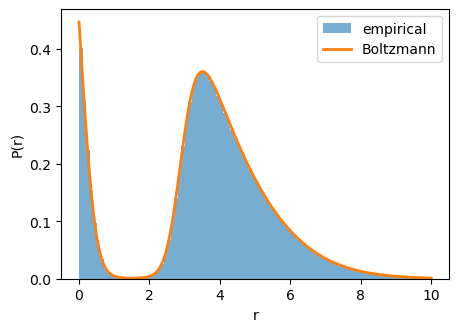

In [11]:
# --- Boltzmann sampling check -----------------------------
burn = int(0.2 * sim.ns)
r_traj = sim.r[burn:, 0, :]                          # shape (n, N)

# samples = r_traj[mask]
samples = r_traj.flatten()

# Boltzmann on the left basin (renormalized over r < x_bar)
xs = np.linspace(1e-2, 10, 5000)
left_mask = xs < x_bar
# P_left = np.exp(-(U_vals - U_well) / T_bath)  * left_mask
# P_left /= np.trapz(P_left, xs)

# Boltzmann on the whole support
P_full = np.exp(-(U_vals - U_well) / T_bath)
P_full /= np.trapz(P_full, xs)

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.hist(samples, bins=100, density=True, range=(r_min, 10), alpha=0.6,
        label="empirical")
ax.plot(xs, P_full, lw=2, label="Boltzmann")
ax.set_xlabel("r"); ax.set_ylabel("P(r)"); ax.legend()

In [ ]:
out_dir = "media/figures/20260606"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "empirical_vs_boltzmann_for_arbitrary_potential_high_T.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260606/empirical_vs_boltzmann_for_arbitrary_potential_high_T.pdf


#### Recovering the Kramers exit rate

In [12]:
r_traj = sim.r[:, 0, :]
limit = x_bar
crossed = r_traj > limit
first_exit = np.where(crossed.any(0), crossed.argmax(0), sim.ns)
mask = np.arange(sim.ns)[burn:, None] < first_exit[None, :]

1000/1000 trajectories exited
empirical rate  k = 1/<T_exit> = 0.0020
Kramers   rate  k             = 0.0022
ratio empirical / Kramers     = 0.94


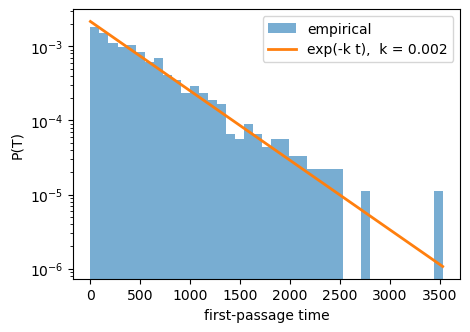

In [13]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
exited = (sim.r[:, 0, :] > limit).any(0)
fpt = first_exit[exited] * sim.dt * sim.nskip
print(f"{exited.sum()}/{sim.N} trajectories exited")

D = (kB * T_bath) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 2.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 40)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")

### Rouse potential + attractive well

In [24]:
from viz_util.bvp_solver import (
    Parameters, d2fb_dphi2, 
)

p = Parameters(
    nb=1.0,
    chi_b=2.5,
    omega_b=-0.6,
    kappa=1,
    phi_inf=0.1,
    L=10.0,
    eps=1e-6,
    R=2.5,
    conserve_volume=False,
    parallel_plates=False
)

kuhnLength = 1
beadSep = 100

barrier    : r=3.107,  U=-2.208,  ω_bar =1.820
ΔU = 3.873


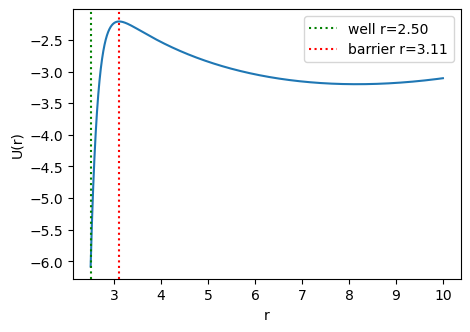

In [25]:
def U(r, *args):
    R, h0, kappa, lam, a, s = args

    # profile = np.where(r >= R, np.exp(-lam*(r-R))*R/r, 1)
    profile = np.exp(-lam*(r-R))*R/r

    return (
        - 2 * np.log(r) + 3*r**2/(2*s*a**2) 
        - 4*np.pi*R**2*h0**2*profile/(kappa*(lam+1/R))
    )

def F(r, *args):
    """Analytic force F = -dU/dx (only valid for x > 0)."""
    R, h0, kappa, lam, a, s = args

    # attrForce = np.where(r >= R, 1, 0)
    attrForce = 1

    return (
        2 / r - 3*r/(s*a**2) 
        - attrForce*4*np.pi*R**3*h0**2*np.exp(-lam*(r-R))*(lam/r+1/r**2)/(kappa*(lam+1/R))
    )

# --- locate left well, barrier; compute ΔU and curvatures ---
xs = np.linspace(p.R, p.L, 5000)

lam = d2fb_dphi2(p.phi_inf, p)
args = (p.R, p.omega_b, p.kappa, lam, kuhnLength, beadSep)
U_vals = U(xs, *args)

# left = xs < 10
i_well = np.argmin(U_vals)
x_well, U_well = xs[i_well], U_vals[i_well]

# Barrier = first zero-crossing of dU/dx past the well.
# At a maximum the force F = -dU/dx flips from - to +; the first sign change
# of F (scanning outward from the well) marks the ridge between the two wells.
F_vals = F(xs, *args)
after_well = xs > x_well
sign_change = (np.sign(F_vals[after_well][:-1]) < 0) & (np.sign(F_vals[after_well][1:]) > 0)
i_cross = np.argmax(sign_change)  # first True; argmax stops at the first one
assert sign_change.any(), "no F-sign-change found past the well — barrier not located"

# linear interpolation between the bracketing samples for a sub-grid root
x_lo = xs[after_well][i_cross]
x_hi = xs[after_well][i_cross + 1]
F_lo, F_hi = F_vals[after_well][i_cross], F_vals[after_well][i_cross + 1]
x_bar = x_lo - F_lo * (x_hi - x_lo) / (F_hi - F_lo)
U_bar = U(x_bar, *args)

dU = U_bar - U_well

# numerical curvatures
def d2U(x):
    h = 1e-3
    return (U(x + h, *args) - 2 * U(x, *args) + U(x - h, *args)) / h**2

# omega_well = np.sqrt(d2U(x_well))  # >0
omega_bar = np.sqrt(-d2U(x_bar))  # |U''| at the saddle

# print(f"left well  : r={x_well:.3f}, U={U_well:.3f}, ω_well={omega_well:.3f}")
print(f"barrier    : r={x_bar:.3f},  U={U_bar:.3f},  ω_bar ={omega_bar:.3f}")
print(f"ΔU = {dU:.3f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.plot(xs, U_vals)
ax.axvline(x_well, color="g", ls=":", label=f"well r={x_well:.2f}")
ax.axvline(x_bar, color="r", ls=":", label=f"barrier r={x_bar:.2f}")
ax.set_xlabel("r")
ax.set_ylabel("U(r)")
# ax.set_ylim(-3.5, -2.4)
ax.legend()


#### Simulating Langevin

In [26]:
# --- parameter selection -------------------------------------------------
# 1) Temperature: ΔU/(kBT) in [3, 7] is the Arrhenius sweet spot --- escape
#    is rare enough to be exponentially distributed, frequent enough to
#    collect statistics in reasonable wall-clock time.
T_bath = 1.2                    # -> ΔU/T ≈ 4.6 here
gamma  = 2.0
kB     = 1.0

# 2) Time step: needs to satisfy BOTH
#       dt < (1/10) * γ / max|U''|         (drift stability)
#       √(2 kBT/γ * dt) << min feature size (noise step << well width)
dV_R = -F(p.R, *args)
relax_well = gamma*kB*T_bath / dV_R**2             # γ / U''(well)
relax_bar  = gamma / abs(d2U(x_bar))          # γ / |U''(barrier)|
dt_drift   = 0.05 * min(relax_well, relax_bar)
noise_step_target = 0.1 * (x_bar - x_well)    # << 1/10 of well-to-barrier distance
dt_noise   = noise_step_target ** 2 / (2 * kB * T_bath / gamma)
dt         = min(dt_drift, dt_noise)
print(f"dt_drift = {dt_drift:.4f}, dt_noise = {dt_noise:.4f}  ->  using dt = {dt:.4f}")

# 3) Total time: a few mean Kramers escape times so we observe many exits.
# tau_K = (2 * np.pi * gamma / (omega_well * omega_bar)) * np.exp(dU / (kB * T_bath))

tau_K = ((gamma / dV_R) * (np.sqrt(2*np.pi*kB*T_bath)/omega_bar) 
         * np.exp(dU / (kB*T_bath)) * (1 - np.exp(-dV_R * (x_bar - p.R)/ (kB*T_bath))))
tau   = 500 * tau_K

print(f"Kramers mean exit time ≈ {tau_K:.2f},  using tau = {tau:.1f}")

# 4) Reflecting wall well clear of the 1/r singularity, but where U(r_min) is
#    so high that the equilibrium weight there is negligible (~ exp(-U/T)).
r_min = p.R+0.01
print(f"U(r_min)/T = {U(r_min, *args)/T_bath:.1f}  (should be >> 1)")

# 5) Number of trajectories — limited by RAM: shape (n, dim, N).
N = 5000
nskip = 100
print(f"n_steps = {int(tau/dt)},  memory ≈ {int(tau/dt)*N*8/1e6/nskip:.0f} MB per array")

sim = OverdampedHarmonicLangevin(
    tau=tau, dim=1, N=N, dt=dt,
    T=T_bath, gamma=gamma, kB=kB,
    F=lambda r: F(r, *args),
    r0=p.R,
    r_min=r_min,
    seed=1,
    nskip=nskip
)
sim.generate()

print("min(r) =", sim.r.min(), " (should be ≥ r_min)")

dt_drift = 0.0002, dt_noise = 0.0031  ->  using dt = 0.0002
Kramers mean exit time ≈ 2.76,  using tau = 1381.1
U(r_min)/T = -4.8  (should be >> 1)
n_steps = 8735031,  memory ≈ 3494 MB per array
min(r) = 2.5  (should be ≥ r_min)


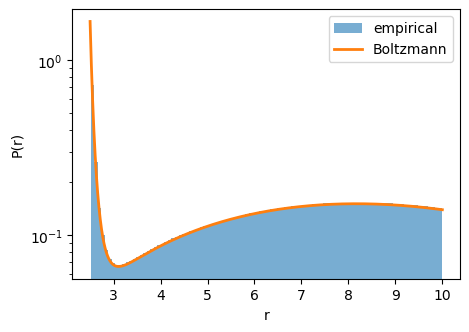

In [27]:
# --- Boltzmann sampling check -----------------------------
burn = int(0.2 * sim.ns)
r_traj = sim.r[burn:, 0, :]                          # shape (n, N)

# samples = r_traj[mask]
samples = r_traj.flatten()

# Boltzmann on the left basin (renormalized over r < x_bar)
# xs = np.linspace(1e-2, 10, 5000)
left_mask = xs < x_bar
# P_left = np.exp(-(U_vals - U_well) / T_bath)  * left_mask
# P_left /= np.trapz(P_left, xs)

# Boltzmann on the whole support
P_full = np.exp(-(U_vals - U_well) / T_bath)
P_full /= np.trapz(P_full, xs)

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.hist(samples, bins=100, density=True, range=(r_min, p.L), alpha=0.6,
        label="empirical")
ax.plot(xs, P_full, lw=2, label="Boltzmann")
ax.set_yscale('log')
ax.set_xlabel("r"); ax.set_ylabel("P(r)"); ax.legend()

#### Kramers exit rate

In [ ]:
ax.plot(t_grid_distance, distance_traj[15])

In [30]:
# r_traj = sim.r[:, 0, :]
r_traj = distance_traj[15]
limit = x_bar
crossed = r_traj > limit
first_exit = np.where(crossed.any(0), crossed.argmax(0), len(r_traj))
mask = np.arange(len(r_traj))[burn:, None] < first_exit[None, :]

NameError: name 'x_bar' is not defined

5000/5000 trajectories exited
empirical rate  k = 1/<T_exit> = 0.8532
Kramers   rate  k             = 0.7241
ratio empirical / Kramers     = 1.18


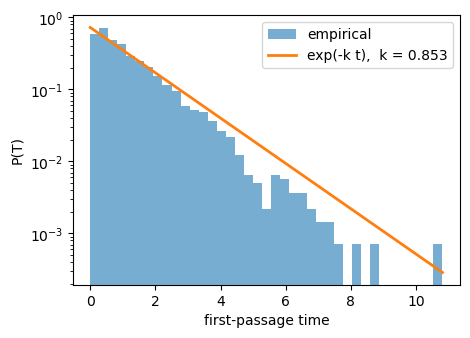

In [29]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
exited = (sim.r[:, 0, :] > limit).any(0)
fpt = first_exit[exited] * sim.dt * sim.nskip
print(f"{exited.sum()}/{sim.N} trajectories exited")

D = (kB * T_bath) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 2.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 40)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")